# 04 · Biological Neurons, McCulloch–Pitts Neurons and Perceptrons

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/04-neurons-perceptrons/04_neurons_perceptrons.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-04-neurons-perceptrons.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 04](https://github.com/anuxlab/deep-learning-systems/wiki/Module-04) |
| **Level** | Beginner |
| **Typical CPU runtime** | < 1 min (GitHub free runner, no GPU) |
| **Prerequisites** | Module 01 |

## What you will do

- Implement McCulloch–Pitts threshold neurons for AND, OR, NOT, NAND.
- Run the perceptron learning algorithm and verify Novikoff's mistake bound $(R/\gamma)^2$.
- Visualise the decision hyperplane $w^\top x+b=0$.
- Prove-by-search that XOR is not linearly separable, then solve it with a two-layer network.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

16:01:05 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43902553858
          commit: b6b1264fa699bf9de0cf3c7dabc0f33416a9092d


## 1 · McCulloch–Pitts neuron
A binary threshold unit: $y=\mathbb 1[\sum_i w_ix_i\ge\theta]$. Excitatory inputs have $w>0$, inhibitory $w<0$. With suitable weights it computes Boolean gates — the first "neural" model of computation (1943).

In [2]:
import itertools
def mp(x, w, theta): return int(np.dot(w, x) >= theta)
gates = {"AND": ([1, 1], 2), "OR": ([1, 1], 1), "NOT x1": ([-1, 0], 0), "NAND": ([-1, -1], -1)}
inputs = list(itertools.product([0, 1], repeat=2))
truth = {"AND": lambda a, b: a & b, "OR": lambda a, b: a | b, "NOT x1": lambda a, b: 1 - a, "NAND": lambda a, b: 1 - (a & b)}
for name, (w, th) in gates.items():
    outs = [mp(np.array(x), np.array(w), th) for x in inputs]
    print(f"{name:7s} w={w} θ={th} ->", outs)
    check(outs == [truth[name](*x) for x in inputs], f"MP neuron implements {name}")

AND     w=[1, 1] θ=2 -> [0, 0, 0, 1]
  ✅ MP neuron implements AND
OR      w=[1, 1] θ=1 -> [0, 1, 1, 1]
  ✅ MP neuron implements OR
NOT x1  w=[-1, 0] θ=0 -> [1, 1, 0, 0]
  ✅ MP neuron implements NOT x1
NAND    w=[-1, -1] θ=-1 -> [1, 1, 1, 0]
  ✅ MP neuron implements NAND


## 2 · Geometry: the decision boundary is a hyperplane
$w^\top x+b=0$ splits the plane in two; $w$ is the normal vector and $|b|/\|w\|$ is the distance from the origin. Below: the AND gate boundary $x_1+x_2-1.5=0$.

16:01:07 | INFO | figure saved -> figures/and_gate_boundary.png


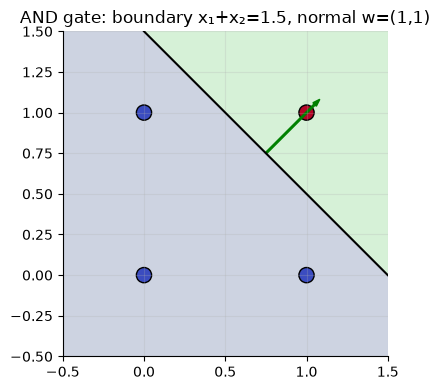

In [3]:
xx, yy = np.meshgrid(np.linspace(-.5, 1.5, 200), np.linspace(-.5, 1.5, 200))
zz = (xx + yy - 1.5 >= 0).astype(int)
plt.contourf(xx, yy, zz, alpha=.25, levels=[-.5, .5, 1.5]); plt.plot([0, 1.5], [1.5, 0], "k")
pts = np.array(inputs); lab = np.array([a & b for a, b in inputs])
plt.scatter(pts[:, 0], pts[:, 1], c=lab, cmap="coolwarm", s=120, edgecolor="k"); plt.arrow(.75, .75, .3, .3, width=.01, color="g")
plt.title("AND gate: boundary x₁+x₂=1.5, normal w=(1,1)"); plt.gca().set_aspect("equal"); show("and_gate_boundary")

## 3 · The perceptron learning algorithm
For labels $y_i\in\{-1,+1\}$: predict $\hat y=\mathrm{sign}(w^\top x+b)$; on a **mistake** ($y_i(w^\top x_i+b)\le0$) update $w\leftarrow w+y_ix_i,\ b\leftarrow b+y_i$.

**Novikoff's theorem:** if the data are linearly separable with margin $\gamma$ (i.e. a unit $w^*$ with $y_i\,w^{*\top}x_i\ge\gamma$) and $\|x_i\|\le R$, the algorithm makes at most $(R/\gamma)^2$ mistakes — regardless of the number of points. We run it and compare the actual mistake count with the bound.

converged in 2 epochs, total mistakes = 6, accuracy = 1.000
  ✅ perceptron separates the training data perfectly
R=15.64  γ=0.303  bound (R/γ)² = 2659.9  >= actual mistakes 6
  ✅ mistake count respects the Novikoff bound (γ measured from the learned separator)


16:01:07 | INFO | figure saved -> figures/perceptron_training.png


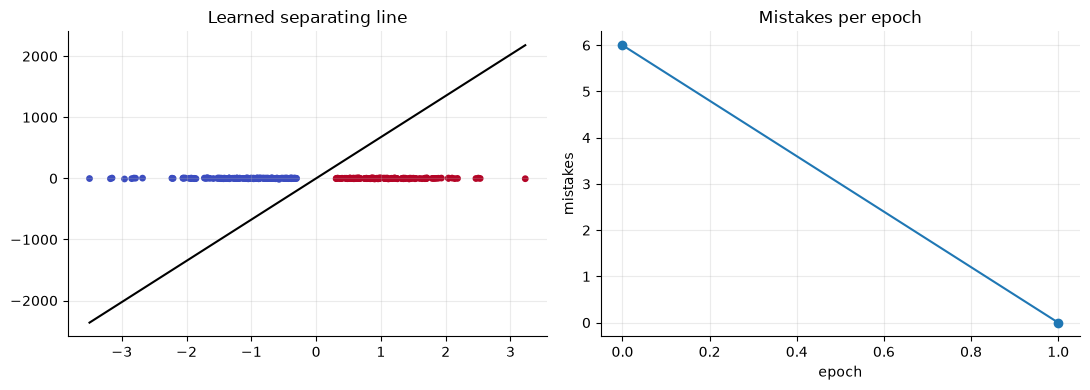

In [4]:
def make_blobs(n=300, gap=0.3, seed=0):
    r = np.random.default_rng(seed)
    y = np.where(r.random(n) < .5, 1, -1)
    X = 4 * r.normal(size=(n, 2)); X[:, 0] = y * (gap + np.abs(r.normal(size=n)))   # guaranteed margin >= gap along x1
    return X, y
X, y = make_blobs()
def perceptron(X, y, epochs=100):
    w, b, mistakes, hist = np.zeros(X.shape[1]), 0.0, 0, []
    for ep in range(epochs):
        errs = 0
        for i in np.random.default_rng(ep).permutation(len(X)):
            if y[i] * (X[i] @ w + b) <= 0:
                w += y[i] * X[i]; b += y[i]; errs += 1
        mistakes += errs; hist.append(errs)
        if errs == 0: break
    return w, b, mistakes, hist
w, b, mistakes, hist = perceptron(X, y)
acc = np.mean(np.sign(X @ w + b) == y)
print(f"converged in {len(hist)} epochs, total mistakes = {mistakes}, accuracy = {acc:.3f}")
check(acc == 1.0 and hist[-1] == 0, "perceptron separates the training data perfectly")

# Novikoff bound: augment with bias so that the separator is a unit vector through the origin
Xa = np.hstack([X, np.ones((len(X), 1))]); R = np.linalg.norm(Xa, axis=1).max()
wstar = np.append(w, b) / np.linalg.norm(np.append(w, b)); gamma = (y * (Xa @ wstar)).min()
bound = (R / gamma) ** 2
print(f"R={R:.2f}  γ={gamma:.3f}  bound (R/γ)² = {bound:.1f}  >= actual mistakes {mistakes}")
check(mistakes <= bound, "mistake count respects the Novikoff bound (γ measured from the learned separator)")
METRICS.update(perceptron_mistakes=mistakes, novikoff_bound=bound)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(*X.T, c=y, cmap="coolwarm", s=15); t = np.linspace(X[:, 0].min(), X[:, 0].max(), 10)
ax[0].plot(t, -(w[0] * t + b) / w[1], "k"); ax[0].set_title("Learned separating line")
ax[1].plot(hist, "o-"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mistakes"); ax[1].set_title("Mistakes per epoch")
show("perceptron_training")

### Effect of the margin
A smaller gap between the classes means a smaller margin $\gamma$, so the bound — and the typical mistake count — grows.

In [5]:
gaps = [1.0, 0.5, 0.25, 0.12, 0.06]; res = []
for g in gaps:
    Xg, yg = make_blobs(gap=g, seed=1)
    w_, b_, m_, h_ = perceptron(Xg, yg, 2000)
    res.append((g, m_, h_[-1] == 0))
    print(f"gap={g}: mistakes={m_:5d} converged={h_[-1]==0}")
check(res[0][1] < res[-1][1] or not res[-1][2], "narrower margin -> more mistakes (or no separation)")

gap=1.0: mistakes=   10 converged=True
gap=0.5: mistakes=   11 converged=True
gap=0.25: mistakes=   15 converged=True
gap=0.12: mistakes=   53 converged=True
gap=0.06: mistakes=   51 converged=True
  ✅ narrower margin -> more mistakes (or no separation)


## 4 · XOR is not linearly separable
Suppose $w_1x_1+w_2x_2+b$ computed XOR. The four points need $b<0$, $w_1+b>0$, $w_2+b>0$, $w_1+w_2+b<0$. Adding the middle two: $w_1+w_2+2b>0$; subtracting $b<0$... gives $w_1+w_2+b>-b>0$, contradicting the last. We also **brute-force** a dense grid of $(w_1,w_2,b)$ to see no single threshold unit works.

In [6]:
XOR_in = np.array(inputs); XOR_y = np.array([a ^ b for a, b in inputs])
grid = np.linspace(-3, 3, 61); found = 0; best = 0
for w1, w2, b_ in itertools.product(grid, grid, grid):
    pred = (XOR_in @ np.array([w1, w2]) + b_ > 0).astype(int)
    best = max(best, (pred == XOR_y).sum())
    found += (pred == XOR_y).all()
print(f"best accuracy over {61**3:,} single-neuron configurations: {best}/4 ; perfect solutions: {found}")
check(found == 0 and best == 3, "no single neuron computes XOR (best possible is 3/4)")

best accuracy over 226,981 single-neuron configurations: 3/4 ; perfect solutions: 0
  ✅ no single neuron computes XOR (best possible is 3/4)


### Two layers solve XOR
$\mathrm{XOR}(a,b)=\mathrm{AND}(\mathrm{OR}(a,b),\mathrm{NAND}(a,b))$. The hidden layer **re-represents** the inputs so the classes become linearly separable — the central idea of deep learning.

XOR net outputs: [0, 1, 1, 0] expected: [np.int64(0), np.int64(1), np.int64(1), np.int64(0)]
  ✅ two-layer MP network computes XOR
16:01:10 | INFO | figure saved -> figures/xor_hidden_space.png


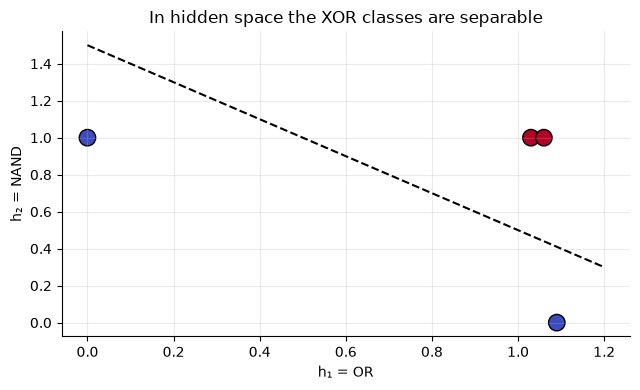

In [7]:
def xor_net(x):
    h = np.array([mp(x, [1, 1], 1), mp(x, [-1, -1], -1)])     # OR, NAND
    return mp(h, [1, 1], 2)                                    # AND
outs = [xor_net(np.array(x)) for x in inputs]; print("XOR net outputs:", outs, "expected:", list(XOR_y))
check(outs == list(XOR_y), "two-layer MP network computes XOR")
H = np.array([[mp(np.array(x), [1, 1], 1), mp(np.array(x), [-1, -1], -1)] for x in inputs])
plt.scatter(H[:, 0] + .03 * np.arange(4), H[:, 1], c=XOR_y, cmap="coolwarm", s=140, edgecolor="k"); plt.plot([0, 1.2], [1.5, .3], "k--")
plt.xlabel("h₁ = OR"); plt.ylabel("h₂ = NAND"); plt.title("In hidden space the XOR classes are separable"); show("xor_hidden_space")

In [8]:
save_metrics("04", METRICS)
log.info('notebook 04 finished OK')

16:01:10 | INFO | metrics saved -> metrics.json


16:01:10 | INFO | notebook 04 finished OK


## Wrap-up

## Exercises (do these next)

1. Implement a 3-input majority gate with a single MP neuron.
2. Add a learning rate to the perceptron and show it does not change the mistake count when starting from w=0.
3. Plot how the perceptron's final separator changes with different data orderings.

## Where to read more

- Wiki chapter: [Module 04](https://github.com/anuxlab/deep-learning-systems/wiki/Module-04) (derivations, worked example, Q&A).
- McCulloch & Pitts (1943); Rosenblatt (1958); Minsky & Papert, *Perceptrons* (1969); Novikoff (1962).